Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

In [2]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

In [3]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

In [4]:
from sklearn.ensemble import StackingClassifier

In [5]:
from imblearn.over_sampling import SMOTE

In [9]:
import lightgbm as lgb

Loading Dataset

In [10]:
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')

Basic Info

In [11]:
print(df.shape)
print(df.columns)
print(df.head())
print(df.info())
print(df.isnull().sum())

(7043, 21)
Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No 

In [12]:
# Convert TotalCharges to numeric, see issues
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Check nulls after conversion
print(df.isnull().sum())

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64


In [13]:
# Fill missing TotalCharges with median (or 0 or tenure*MonthlyCharges, discuss later)
df['TotalCharges'].fillna(df['TotalCharges'].median(), inplace=True)

C:\Users\Deepak Dhinwa\AppData\Local\Temp\ipykernel_11376\3468692150.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['TotalCharges'].fillna(df['TotalCharges'].median(), inplace=True)


In [14]:
# Quick target distribution
print(df['Churn'].value_counts())

Churn
No     5174
Yes    1869
Name: count, dtype: int64


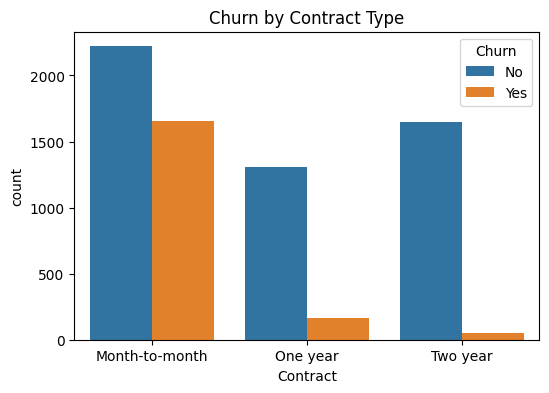

In [15]:
# Visualisation: Churn by Contract type
plt.figure(figsize=(6,4))
sns.countplot(x='Contract', hue='Churn', data=df)
plt.title('Churn by Contract Type')
plt.show()

Data Cleaning & Preprocessing Plan
- Drop customerID (non-informative)
- Encode SeniorCitizen as category or leave as numeric (0,1)
- Encode binary categoricals (gender, Partner, Dependents, etc.)
- One-hot encode multi-categoricals (InternetService, Contract, PaymentMethod, etc.)
- Scale numerical features (tenure, MonthlyCharges, TotalCharges) using StandardScaler or MinMaxScaler

In [16]:
# Drop customerID
df.drop('customerID', axis=1, inplace=True)

# Binary columns to encode
binary_cols = ['gender', 'Partner', 'Dependents', 'PhoneService', 'PaperlessBilling', 'Churn']

# Encode binary cols
le = LabelEncoder()
for col in binary_cols:
    df[col] = le.fit_transform(df[col])

Tenure Group
- Tenure is numeric, but customer behaviour often changes in intervals (e.g. churn in first year vs long-term customers).
- Grouping creates a categorical variable capturing non-linear patterns.

Interaction Features
- Multiplying MonthlyCharges × Tenure captures total revenue value of a customer, relevant for churn strategies.
- Combining Contract + PaymentMethod creates an interaction feature capturing joint influence (e.g. Monthly contract + Electronic check may churn more).

In [17]:
# Feature engineering: tenure group
df['tenure_group'] = pd.cut(df['tenure'], bins=[0,12,24,36,48,60,72], labels=['0-12','12-24','24-36','36-48','48-60','60-72'])

# Interaction features
df['MonthlyCharges_Tenure'] = df['MonthlyCharges'] * df['tenure']
df['Contract_PaymentMethod'] = df['Contract'] + "_" + df['PaymentMethod']

# Check new features
print(df[['tenure','tenure_group','MonthlyCharges_Tenure','Contract_PaymentMethod']].head())

   tenure tenure_group  MonthlyCharges_Tenure  \
0       1         0-12                  29.85   
1      34        24-36                1936.30   
2       2         0-12                 107.70   
3      45        36-48                1903.50   
4       2         0-12                 141.40   

               Contract_PaymentMethod  
0     Month-to-month_Electronic check  
1               One year_Mailed check  
2         Month-to-month_Mailed check  
3  One year_Bank transfer (automatic)  
4     Month-to-month_Electronic check  


In [18]:
# Features and target
X = df.drop('Churn', axis=1)
y = df['Churn']

In [19]:
# Columns by type
numeric_features = ['tenure', 'MonthlyCharges', 'TotalCharges', 'MonthlyCharges_Tenure']
categorical_features = [col for col in X.columns if X[col].dtype == 'object']
print(categorical_features)

['MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaymentMethod', 'Contract_PaymentMethod']


In [20]:
categorical_features.append('tenure_group')
print(categorical_features)

['MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaymentMethod', 'Contract_PaymentMethod', 'tenure_group']


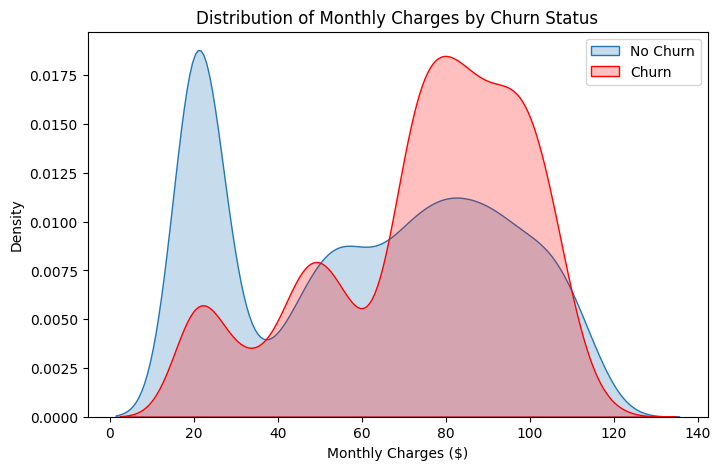

In [40]:
# Distribution plot of Monthly Charges by Churn status
plt.figure(figsize=(8,5))
sns.kdeplot(df[df['Churn']==0]['MonthlyCharges'], label='No Churn', fill=True)
sns.kdeplot(df[df['Churn']==1]['MonthlyCharges'], label='Churn', fill=True, color='red')
plt.xlabel('Monthly Charges ($)')
plt.title('Distribution of Monthly Charges by Churn Status')
plt.legend()
plt.show()

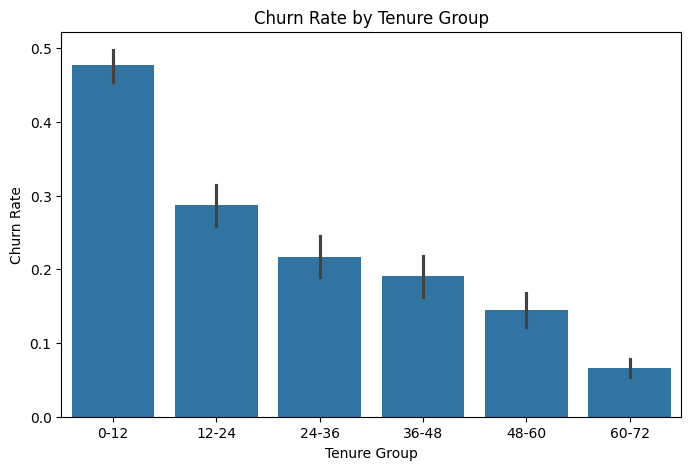

In [21]:
# Plot churn rate by tenure group
plt.figure(figsize=(8,5))
sns.barplot(x='tenure_group', y='Churn', data=df)
plt.title('Churn Rate by Tenure Group')
plt.ylabel('Churn Rate')
plt.xlabel('Tenure Group')
plt.show()

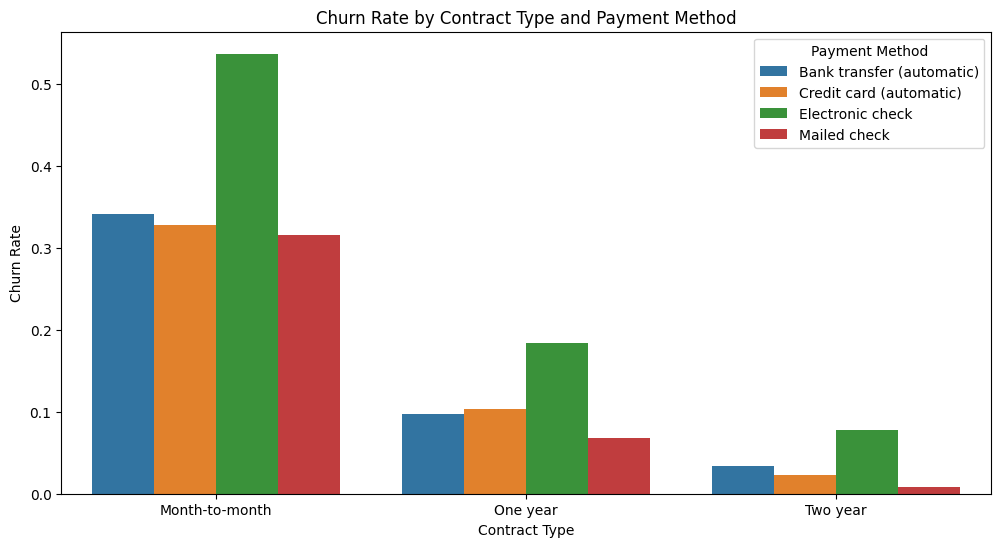

In [22]:
# Group by Contract and PaymentMethod and calculate churn rate
churn_rate = df.groupby(['Contract', 'PaymentMethod'])['Churn'].mean().reset_index()

plt.figure(figsize=(12,6))
sns.barplot(x='Contract', y='Churn', hue='PaymentMethod', data=churn_rate)
plt.title('Churn Rate by Contract Type and Payment Method')
plt.ylabel('Churn Rate')
plt.xlabel('Contract Type')
plt.legend(title='Payment Method')
plt.show()


Churn vs Tenure Group:
- Churn rate decreases steadily with increasing tenure → Customers staying longer are less likely to churn, showing loyalty stabilisation over time.

Churn vs Contract & Payment Method:
- Electronic check payments have the highest churn rate, suggesting potential dissatisfaction or financial instability.
- Bank transfers and credit cards have moderate churn, while mailed checks have the lowest churn, possibly representing an older or more stable customer segment.

Cost-sensitive Modelling and SMOTE
- Recall for class 1 (churn) was only ~54%
- Missing a churner is costlier than a false alarm

Goal: Improve minority class detection via:
- Class weight adjustment: Penalise misclassification of churn more
- SMOTE: Oversample churn class to balance dataset

- Huge improvement in recall (detecting churners)
- Slight drop in precision and accuracy

In [23]:
# Preprocessing pipeline
numeric_transformer = StandardScaler()
categorical_transformer = OneHotEncoder(handle_unknown='ignore')

# handle_unknown='ignore' ensures that if a new category appears during prediction, it will not throw an error but will ignore it safely.

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)])

# Check result
X_preprocessed = preprocessor.fit_transform(X)
print(X_preprocessed.shape)

(7043, 54)


Baseline Model – Logistic Regression

In [24]:
# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X_preprocessed, y, test_size=0.2, random_state=42, stratify=y)

# Model
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train, y_train)

# Predictions
y_pred = lr.predict(X_test)
y_prob = lr.predict_proba(X_test)[:,1]

# Evaluation
print("Classification Report:\n", classification_report(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("ROC-AUC Score:", roc_auc_score(y_test, y_prob))

Classification Report:
               precision    recall  f1-score   support

           0       0.83      0.90      0.87      1035
           1       0.65      0.51      0.57       374

    accuracy                           0.80      1409
   macro avg       0.74      0.70      0.72      1409
weighted avg       0.78      0.80      0.79      1409

Confusion Matrix:
 [[931 104]
 [184 190]]
ROC-AUC Score: 0.8415316851378232


- Accuracy: ~79%
- Recall for churn (class 1): 54% (improvement needed)
- ROC-AUC: ~0.84 (good baseline)

Advanced Models
- Training Random Forest and XGBoost to improve recall and overall performance

In [25]:
# Random Forest
rf = RandomForestClassifier(n_estimators=200, random_state=42)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)
rf_prob = rf.predict_proba(X_test)[:,1]

print("Random Forest ROC-AUC:", roc_auc_score(y_test, rf_prob))
print("Random Forest Classification Report:\n", classification_report(y_test, rf_pred))

Random Forest ROC-AUC: 0.8102392208530317
Random Forest Classification Report:
               precision    recall  f1-score   support

           0       0.83      0.88      0.85      1035
           1       0.59      0.49      0.54       374

    accuracy                           0.78      1409
   macro avg       0.71      0.69      0.70      1409
weighted avg       0.77      0.78      0.77      1409



In [26]:
# XGBoost
xgb = XGBClassifier(use_label_encoder=False, eval_metric='logloss')
xgb.fit(X_train, y_train)
xgb_pred = xgb.predict(X_test)
xgb_prob = xgb.predict_proba(X_test)[:,1]

print("XGBoost ROC-AUC:", roc_auc_score(y_test, xgb_prob))
print("XGBoost Classification Report:\n", classification_report(y_test, xgb_pred))

XGBoost ROC-AUC: 0.8217533390167661
XGBoost Classification Report:
               precision    recall  f1-score   support

           0       0.83      0.86      0.85      1035
           1       0.57      0.52      0.54       374

    accuracy                           0.77      1409
   macro avg       0.70      0.69      0.69      1409
weighted avg       0.76      0.77      0.77      1409



D:\projects\customer_churn_prediction\customer_churn\Lib\site-packages\xgboost\training.py:183: UserWarning: [12:29:18] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


In [27]:
# SMOTE oversampling
sm = SMOTE(random_state=42)
X_res, y_res = sm.fit_resample(X_train, y_train)

# Logistic Regression with class_weight balanced
lr = LogisticRegression(max_iter=1000, class_weight='balanced')
lr.fit(X_res, y_res)
pred = lr.predict(X_test)
prob = lr.predict_proba(X_test)[:,1]

print("SMOTE + Cost-sensitive Logistic Regression")
print("ROC-AUC:", roc_auc_score(y_test, prob))
print(classification_report(y_test, pred))

SMOTE + Cost-sensitive Logistic Regression
ROC-AUC: 0.8411209279495726
              precision    recall  f1-score   support

           0       0.91      0.72      0.80      1035
           1       0.50      0.79      0.62       374

    accuracy                           0.74      1409
   macro avg       0.70      0.76      0.71      1409
weighted avg       0.80      0.74      0.75      1409



LightGBM Model

In [28]:
# LightGBM model
lgbm = lgb.LGBMClassifier(class_weight='balanced', random_state=42)
lgbm.fit(X_train, y_train)
pred = lgbm.predict(X_test)
prob = lgbm.predict_proba(X_test)[:,1]

print("LightGBM ROC-AUC:", roc_auc_score(y_test, prob))
print(classification_report(y_test, pred))


[LightGBM] [Info] Number of positive: 1495, number of negative: 4139
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000504 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 937
[LightGBM] [Info] Number of data points in the train set: 5634, number of used features: 53
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start training from score 0.000000
LightGBM ROC-AUC: 0.8321268955540055
              precision    recall  f1-score   support

           0       0.90      0.75      0.82      1035
           1       0.53      0.77      0.62       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.75      0.77      1409



Model Stacking

In [32]:
# SMOTE oversampling
sm = SMOTE(random_state=42)
X_res, y_res = sm.fit_resample(X_train, y_train)

# Defining base learners with class_weight balanced where applicable
estimators = [
    ('lr', LogisticRegression(max_iter=1000, class_weight='balanced')),
    ('rf', RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42)),
    ('xgb', XGBClassifier(use_label_encoder=False, eval_metric='logloss')),
    ('lgb', lgb.LGBMClassifier(class_weight='balanced', random_state=42))
]

# Stacking classifier with Logistic Regression as final estimator for interpretability
stack = StackingClassifier(
    estimators=estimators,
    final_estimator=LogisticRegression(max_iter=1000, class_weight='balanced')
)

# Fitting on SMOTE-resampled data
stack.fit(X_res, y_res)

# Predictions and evaluation
stack_pred = stack.predict(X_test)
stack_prob = stack.predict_proba(X_test)[:,1]

print("Enhanced Stacking ROC-AUC:", roc_auc_score(y_test, stack_prob))
print("Enhanced Stacking Classification Report:\n", classification_report(y_test, stack_pred))


D:\projects\customer_churn_prediction\customer_churn\Lib\site-packages\xgboost\training.py:183: UserWarning: [12:40:15] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


[LightGBM] [Info] Number of positive: 4139, number of negative: 4139
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001520 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3273
[LightGBM] [Info] Number of data points in the train set: 8278, number of used features: 53
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000


D:\projects\customer_churn_prediction\customer_churn\Lib\site-packages\xgboost\training.py:183: UserWarning: [12:40:58] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
D:\projects\customer_churn_prediction\customer_churn\Lib\site-packages\xgboost\training.py:183: UserWarning: [12:40:59] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


[LightGBM] [Info] Number of positive: 3311, number of negative: 3311
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000632 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 3273
[LightGBM] [Info] Number of data points in the train set: 6622, number of used features: 53
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Number of positive: 3311, number of negative: 3311
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000539 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 3197
[LightGBM] [Info] Number of data points in the train set: 6622, number of used features: 53
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000


- Higher precision (59%) than previous models
- Lower recall (60%) compared to 79% with cost-sensitive LR + SMOTE or 77% with LightGBM

Confusion matrix heatmaps for models

In [41]:
def plot_confusion_matrix_heatmap(y_true, y_pred, model_name):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(5,4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f"{model_name} Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

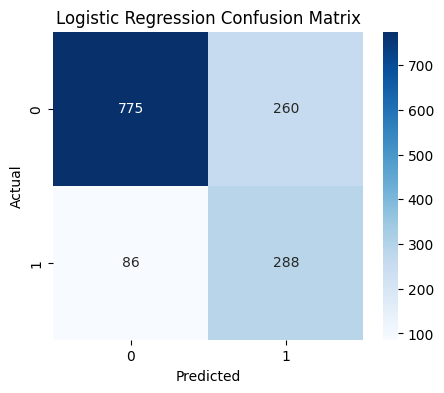

In [45]:
plot_confusion_matrix_heatmap(y_test, pred, "Logistic Regression")

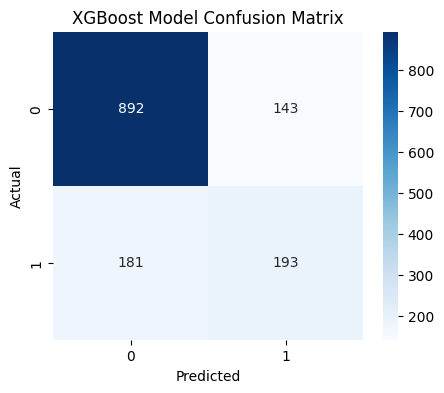

In [43]:
plot_confusion_matrix_heatmap(y_test, xgb_pred, "XGBoost Model")

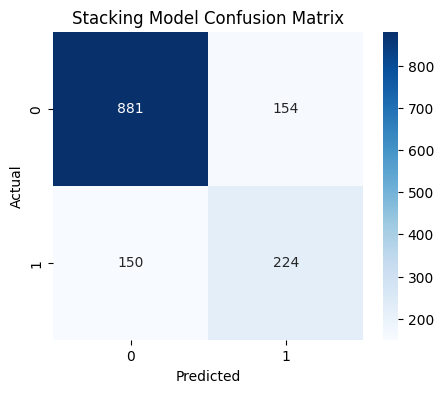

In [42]:
plot_confusion_matrix_heatmap(y_test, stack_pred, "Stacking Model")

In [33]:
import shap

54 54


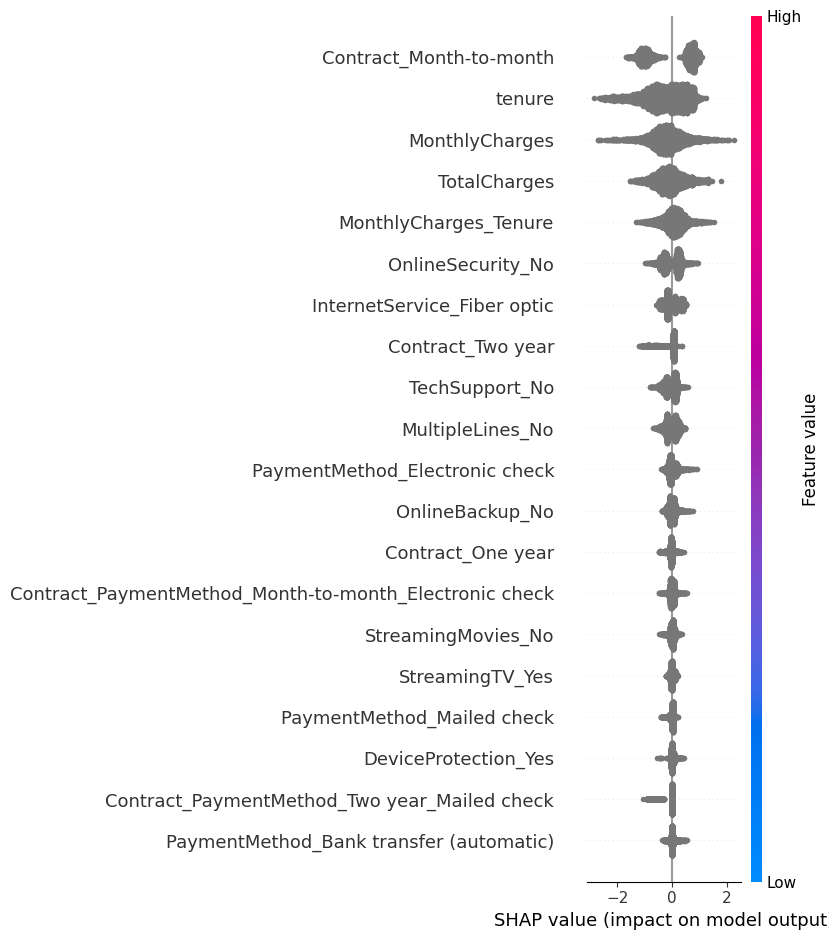

In [35]:
# If using preprocessed data, create encoded feature names
encoded_feature_names = []

# Numerical features remain same
encoded_feature_names += numeric_features

# For one-hot encoded categoricals, get categories from OneHotEncoder
ohe = preprocessor.named_transformers_['cat']
cat_feature_names = ohe.get_feature_names_out(categorical_features)
encoded_feature_names += list(cat_feature_names)

# Check length matches
print(len(encoded_feature_names), X_train.shape[1])

# Plot with correct names
shap.summary_plot(shap_values, X_train, feature_names=encoded_feature_names)


In [36]:
import joblib

In [37]:
# Save stacking pipeline
final_stack_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', stack)
])
final_stack_pipeline.fit(X, y)
joblib.dump(final_stack_pipeline, 'churn_stack_pipeline.pkl')
print("Model pipeline saved")

D:\projects\customer_churn_prediction\customer_churn\Lib\site-packages\xgboost\training.py:183: UserWarning: [16:44:22] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


[LightGBM] [Info] Number of positive: 1869, number of negative: 5174
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000304 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 937
[LightGBM] [Info] Number of data points in the train set: 7043, number of used features: 53
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start training from score 0.000000


D:\projects\customer_churn_prediction\customer_churn\Lib\site-packages\xgboost\training.py:183: UserWarning: [16:44:50] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
D:\projects\customer_churn_prediction\customer_churn\Lib\site-packages\xgboost\training.py:183: UserWarning: [16:44:51] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


[LightGBM] [Info] Number of positive: 1495, number of negative: 4139
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000086 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 937
[LightGBM] [Info] Number of data points in the train set: 5634, number of used features: 53
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start training from score 0.000000
[LightGBM] [Info] Number of positive: 1495, number of negative: 4139
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000285 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 937
[LightGBM] [Info] Number of data points in the train set: 5634, number of used features: 53
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [I